In [43]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("../grunddata/health_study_dataset.csv")

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [45]:
df.isna().sum()

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

Här har jag kontrolerat om det finns nan värden i någon av kategorierna. Det finns det ej. Data settet är komplett.

In [59]:
disease_yes = df[df["disease"] == 1]
disease_no = df[df["disease"] == 0]

df["disease"].value_counts()

disease
0    753
1     47
Name: count, dtype: int64

In [47]:
#Nu vill jag undersöka vilka kategorier som har sjukdommar för en första översikt

pd.crosstab(df["age"], df["disease"])


disease,0,1
age,,
18,10,1
19,3,0
20,3,0
21,4,0
22,2,0
...,...,...
84,2,0
86,2,0
88,2,0


In [48]:
pd.crosstab(df["sex"], df["disease"])


disease,0,1
sex,,
F,385,18
M,368,29


Fler män än kvinnor har sjukdom

In [49]:
pd.crosstab(df["weight"], df["disease"])

disease,0,1
weight,,
33.7,1,0
33.9,1,0
35.5,1,0
38.1,1,0
41.6,1,0
...,...,...
106.6,1,0
106.9,1,0
107.3,2,0


In [50]:
pd.crosstab(df["systolic_bp"], df["disease"])

disease,0,1
systolic_bp,,
106.8,1,0
116.3,1,0
117.1,1,0
117.8,1,0
118.5,1,0
...,...,...
183.3,1,0
183.8,1,0
184.1,1,0


In [51]:
pd.crosstab(df["cholesterol"], df["disease"])

disease,0,1
cholesterol,,
2.50,2,0
2.54,1,0
2.64,1,0
2.78,2,0
2.81,1,0
...,...,...
7.23,1,0
7.36,1,0
7.41,1,0


In [52]:
pd.crosstab(df["smoker"], df["disease"])

disease,0,1
smoker,,
No,559,28
Yes,194,19


In [60]:
pd.crosstab(df["height"], df["disease"])


disease,0,1
height,,
144.4,1,0
146.5,1,0
146.8,1,0
147.1,1,0
147.9,1,0
...,...,...
195.5,1,0
195.9,1,0
196.1,1,1


Här ser vi att jag stöter på problem i visning av antalet sjukdomar i varje kategori. Cholesterol, weight, age och systolic_bp har för många unika värden för att enkelt ge dem ja eller nej på samma sätt som smoker oxh sex ger. Därför behöver jag skapa grafer för dessa kategorier som är otydliga för att se någon koppling. 

Något som är intressant från ovan är att icke rökare är fler än rökare i denna undersökning vad gäller sjukdom.
Andelen män är fler än kvinnor som har sjukdom. 

In [53]:
#gruppera age, cholesterol, weight och systolic_bp

disease_yes.groupby(
    pd.cut(disease_yes["age"], bins=[15, 25, 30, 35, 40, 45, 50, 55, 60, 70, 80, 90, 100])
).size()

age
(15, 25]     1
(25, 30]     2
(30, 35]     2
(35, 40]     5
(40, 45]     6
(45, 50]     7
(50, 55]    11
(55, 60]     3
(60, 70]     6
(70, 80]     3
(80, 90]     1
dtype: int64

In [54]:
disease_yes.groupby(
    pd.cut(disease_yes["cholesterol"], bins=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
).size()

cholesterol
(2, 3]     1
(3, 4]     3
(4, 5]    21
(5, 6]    19
(6, 7]     3
dtype: int64

In [55]:
disease_yes.groupby(
    pd.cut(disease_yes["weight"], bins=[0, 20, 30, 40, 50,  60, 70, 75, 80, 90, 100, 110, 130])
).size()

weight
(50, 60]       6
(60, 70]       6
(70, 75]      11
(75, 80]      10
(80, 90]      10
(90, 100]      3
(100, 110]     1
dtype: int64

In [56]:
disease_yes.groupby(
    pd.cut(disease_yes["systolic_bp"], bins=[50, 80, 100, 105, 110, 115, 120, 130, 140, 150, 160, 180, 200, 210])
).size()

systolic_bp
(120, 130]     4
(130, 140]     5
(140, 150]    14
(150, 160]    14
(160, 180]     9
(180, 200]     1
dtype: int64

In [62]:
disease_yes.groupby(
    pd.cut(disease_yes["height"], bins=[130, 140, 150, 160, 170, 180, 190, 200, 210])
).size()

height
(150, 160]     4
(160, 170]    13
(170, 180]    17
(180, 190]    11
(190, 200]     2
dtype: int64

I denna sortering ser vi att de som är sjuka är mellan 50-55 år, väger mellan 70-80 kg, har ett cholestrolvärde mellan 4-5 och blodtryck mellan 140-160. Där har vi vår riskzon. Om patienten dessutom är man är det ytterligare en indikator på risk.

In [63]:
#boxplot för ja och nej sjuk. för varje kategori. median och extremvärden. 

df.groupby("disease")[["age", "weight", "systolic_bp", "cholesterol", "height"]].describe()

age                                                     weight  \
         count       mean        std   min   25%   50%   75%   max  count   
disease                                                                     
0        753.0  49.347942  14.547101  18.0  39.0  50.0  59.0  90.0  753.0   
1         47.0  50.680851  13.831449  18.0  42.0  51.0  56.5  90.0   47.0   

                    ... cholesterol       height                               \
              mean  ...         75%   max  count        mean       std    min   
disease             ...                                                         
0        73.285126  ...       5.480  7.88  753.0  171.767995  9.805052  144.4   
1        75.461702  ...       5.495  6.96   47.0  173.151064  9.804056  152.6   

                                      
            25%    50%    75%    max  
disease                               
0        164.70  171.3  178.9  200.4  
1        166.45  172.8  181.1  196.1  

[2 rows x 40 columns]

Ovan ser vi andelar för varje kategori. Medelvärde, standardavvikelse, max, min, kvartiler och antal för varje kategori baserat på sjuk = ja (1) eller nej (0)

Eftersom det är lite svårt att avläsa detta så ska jag bygga grafik på samma data. 

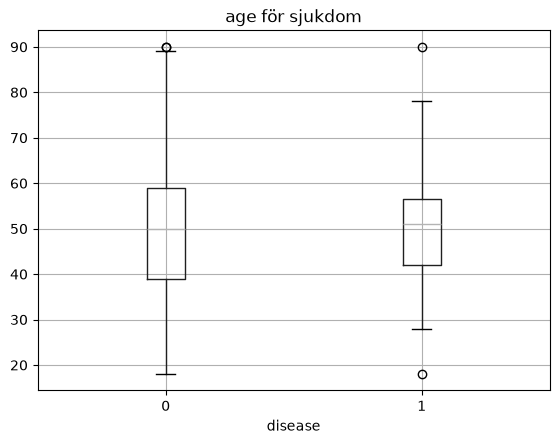

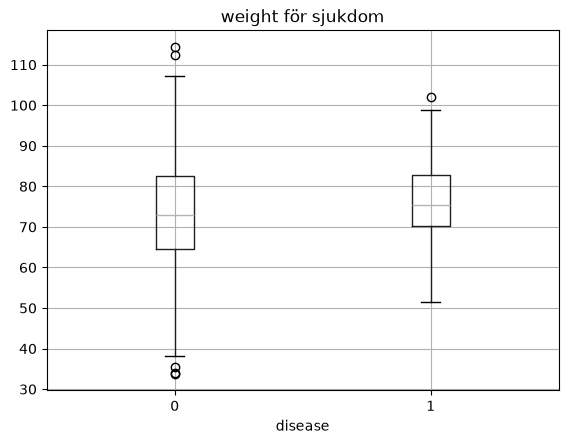

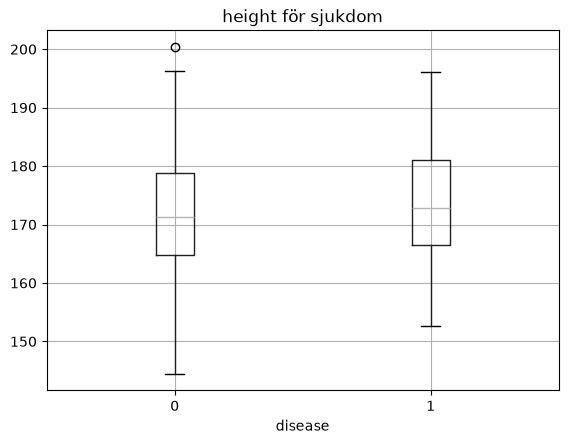

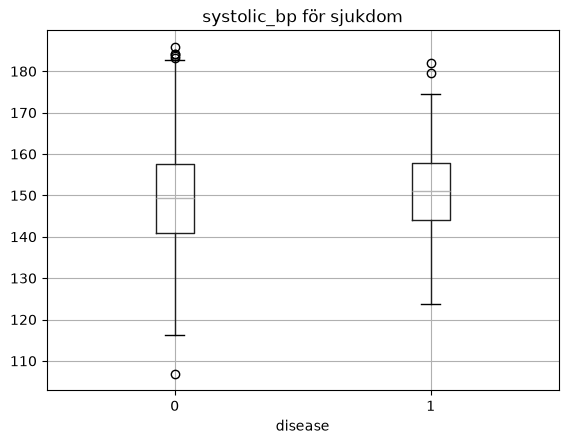

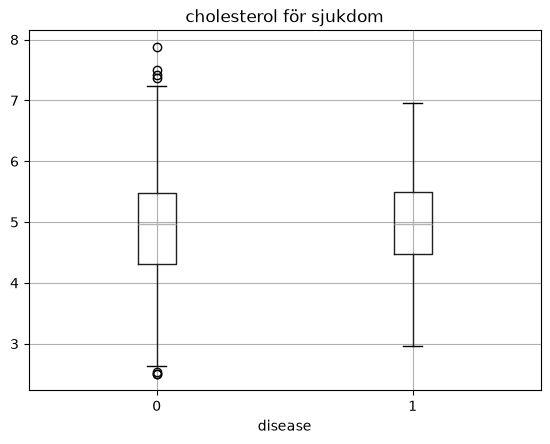

In [64]:
columns = ["age", "weight", "height", "systolic_bp", "cholesterol"]

for col in columns:
    df.boxplot(column=col, by="disease")
    plt.title(f"{col} för sjukdom")
    plt.suptitle("")
    plt.show

## räkna ut bmi och jämför sjuka inte sjuka osv